# 07 — Tableaux comparatifs finals, test de robustesse et conclusions

**Responsable : toute l'équipe (consolidation)** · Entrées : `reports/results/*.json` (notebooks 01 à 06) et modèles de `models/`.

Règles de ce notebook :
- **aucun chiffre saisi à la main** : tous les tableaux sont construits à partir des fichiers JSON des notebooks précédents, et les commentaires chiffrés sont générés par du code à partir des sorties réelles ;
- tous les modèles sont évalués sur le **même jeu de test**, qui n'a servi à choisir ni un modèle, ni un seuil, ni un hyper-paramètre (voir `reports/AUDIT.md` pour les défauts corrigés par rapport à la première version) ;
- la section 5 (test de robustesse / raccourcis) n'utilise **que le jeu de validation** : le test n'y est jamais lu.

In [1]:
import sys, warnings, joblib, time, textwrap
sys.path.append("../src")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display, Markdown
import ml_utils as U
U.set_style(); U.set_seeds()
warnings.filterwarnings("ignore")

R = U.load_results()
print("Résultats disponibles :", list(R))
prep, cfg = R["prep"], U.load_config()
REPORT = U.REPORT_DIR

Résultats disponibles : ['02_rf_anomaly', '03_svm_anomaly', '04_rf_regressor', '05_xgb_regressor', '06_isolation_forest', '07_robustness', 'prep']


## 1. Données et protocole (lu dans `prep.json`)

Ce résumé rappelle d'où viennent les lignes utilisées : la **déduplication** réduit fortement le jeu brut (beaucoup de flux identiques), et un dernier passage **inter-splits** garantit qu'aucune ligne de validation ou de test n'est identique à une ligne d'entraînement dans l'espace final des variables.

In [2]:
chaine = pd.DataFrame([
    ("Lignes brutes", prep["n_rows_raw"]),
    ("Après déduplication (espace des variables candidates + cibles)", prep["n_rows_after_exact_dedup"]),
    ("Après retrait des conflits (mêmes variables, types différents)", prep["n_rows_clean"]),
    ("Split initial 60/20/20 — train", prep["split_sizes_initial"]["train"]),
    ("Split initial — validation", prep["split_sizes_initial"]["valid"]),
    ("Split initial — test", prep["split_sizes_initial"]["test"]),
    ("Retirées de la validation (doublons d'une ligne du train)", prep["n_dropped_valid_cross_split"]),
    ("Retirées du test (doublons d'une ligne du train ∪ validation)", prep["n_dropped_test_cross_split"]),
    ("FINAL — train", prep["split_sizes"]["train"]),
    ("FINAL — validation", prep["split_sizes"]["valid"]),
    ("FINAL — test", prep["split_sizes"]["test"]),
], columns=["étape", "lignes"]).set_index("étape")
display(chaine.style.format("{:,.0f}"))

ov = pd.DataFrame({"avant (%)": prep["overlap_before_pct"], "après (%)": prep["overlap_after_pct"]})
display(ov.style.format("{:.3f}"))
assert all(v == 0 for v in prep["overlap_after_pct"].values()), "chevauchement résiduel entre splits"

print(f"Variables : {prep['n_features']} ({len(prep['numeric_cols'])} numériques, {len(prep['categorical_cols'])} catégorielles) ; "
      f"colonnes retirées : {len(prep['removed_columns'])} (IP, port source, colonnes quasi vides, texte à forte cardinalité...)")
print(f"Ordre des types retenu pour la régression : {prep['type_order']}")
print(f"Source de l'ordre : {prep['type_order_source']} "
      f"(gain de F1 macro vs ordre documenté = {prep['encoding_gain_vs_documented']:.4f}, "
      f"écart-type des permutations aléatoires = {prep['encoding_random_std']:.4f})")

,lignes
étape,
Lignes brutes,"211,043"
Après déduplication (espace des variables candidates + cibles),"108,636"
"Après retrait des conflits (mêmes variables, types différents)","108,346"
Split initial 60/20/20 — train,"65,007"
Split initial — validation,"21,669"
Split initial — test,"21,670"
Retirées de la validation (doublons d'une ligne du train),187
Retirées du test (doublons d'une ligne du train ∪ validation),232
FINAL — train,"65,007"


,avant (%),après (%)
valid ∩ train,0.863,0.000
test ∩ train,0.835,0.000
test ∩ (train ∪ valid),1.071,0.000


Variables : 35 (26 numériques, 9 catégorielles) ; colonnes retirées : 24 (IP, port source, colonnes quasi vides, texte à forte cardinalité...)
Ordre des types retenu pour la régression : ['normal', 'ransomware', 'scanning', 'backdoor', 'dos', 'mitm', 'xss', 'ddos', 'injection', 'password']
Source de l'ordre : piloté par les données (LDA, train) (gain de F1 macro vs ordre documenté = 0.0182, écart-type des permutations aléatoires = 0.0178)


## 2. Tableau A — détection d'anomalies (cible binaire `label`)

Quatre lignes : Random Forest, SVM (variante retenue en 03), **Isolation Forest A** (non supervisé, aucune étiquette) et **Isolation Forest B** (semi-supervisé : l'entraînement est filtré sur les lignes normales, donc il utilise des étiquettes — signalé dans le nom du modèle).
Le test est évalué **au seuil choisi sur la validation** pour les modèles supervisés (clé `test`) ; Isolation Forest A est évalué à sa décision par défaut (`predict == -1`), sans aucun réglage.

**Lecture du tableau** : à `n_train_rows` différents, les temps d'ajustement ne se comparent pas directement (le SVM RBF exact est limité à 25 000 lignes à cause de son coût O(n²), voir 03). Les colonnes `fit_time_s` et `predict_time_ms_per_1k` sont celles mesurées dans chaque notebook.

In [3]:
def short(items, width=230):
    """Joint des phrases de limites par ' ; ' (sans '|' pour ne pas casser le Markdown) et tronque proprement."""
    s = " ; ".join(t.rstrip(". ") for t in items).replace("|", "/")
    return s if len(s) <= width else textwrap.shorten(s, width=width, placeholder="…")

def strat(s):
    return U.STRATEGY_LABELS.get(s, s)

A_METRICS = ["accuracy", "precision", "recall", "specificity", "f1", "f1_macro", "f1_weighted",
             "roc_auc", "pr_auc", "mcc", "fpr", "fnr"]

def row_A(name, m, n_rows, fit_s, pred_ms, strategy, limits):
    return {"modèle": name, **{k: m[k] for k in A_METRICS}, "n_train_rows": n_rows, "fit_time_s": fit_s,
            "predict_time_ms_per_1k": pred_ms, "strategy": strategy, "limitations": short(limits)}

rf, svm, iso = R["02_rf_anomaly"], R["03_svm_anomaly"], R["06_isolation_forest"]
iso_B = iso["test_semi_supervised"]
iso_B_limits = [iso_B["note"]] + [t for t in iso["limitations"] if "variante B" in t] + \
               [t for t in iso["limitations"] if "Aucun type" in t]
NAME_RF = "Random Forest"
NAME_SVM = svm["params"]["variante"]   # ex. « SVM RBF (25k lignes) »
NAME_IFA = "Isolation Forest A (non supervisé)"
NAME_IFB = "Isolation Forest B (semi-supervisé : train filtré sur normal)"

tab_A = pd.DataFrame([
    row_A(NAME_RF, rf["test"], rf["n_train_rows"], rf["fit_time_s"], rf["predict_time_ms_per_1k"], strat(rf["strategy"]), rf["limitations"]),
    row_A(NAME_SVM, svm["test"], svm["n_train_rows"], svm["fit_time_s"], svm["predict_time_ms_per_1k"], strat(svm["strategy"]), svm["limitations"]),
    row_A(NAME_IFA, iso["test"], iso["n_train_rows"], iso["fit_time_s"], iso["predict_time_ms_per_1k"], iso["strategy"], iso["limitations"]),
    row_A(NAME_IFB, iso_B, iso_B["n_train_rows"], iso_B["fit_time_s"], iso_B["predict_time_ms_per_1k"],
          "aucun (semi-supervisé : filtre label == 0)", iso_B_limits),
])

HIGHER_A = ["accuracy", "precision", "recall", "specificity", "f1", "f1_macro", "f1_weighted", "roc_auc", "pr_auc", "mcc"]
LOWER_A = ["fpr", "fnr", "fit_time_s", "predict_time_ms_per_1k"]

def styled(df, higher, lower):
    d = df.set_index("modèle").drop(columns=["limitations"])
    fmt = {c: "{:.4f}" for c in d.select_dtypes("number").columns}; fmt["n_train_rows"] = "{:,.0f}"
    return (d.style.format(fmt, na_rep="–")
            .highlight_max(subset=higher, color="#c6efce", axis=0)
            .highlight_min(subset=lower, color="#c6efce", axis=0))

display(styled(tab_A, HIGHER_A, LOWER_A))

,accuracy,precision,recall,specificity,f1,f1_macro,f1_weighted,roc_auc,pr_auc,mcc,fpr,fnr,n_train_rows,fit_time_s,predict_time_ms_per_1k,strategy
modèle,,,,,,,,,,,,,,,,
Random Forest,0.9984,0.9992,0.9988,0.9971,0.9990,0.9977,0.9984,1.0000,1.0000,0.9955,0.0029,0.0012,"65,007",6.4315,11.3984,Aucun
SVM RBF (25k lignes),0.9965,0.9981,0.9973,0.9936,0.9977,0.9950,0.9965,0.9989,0.9994,0.9899,0.0064,0.0027,"25,000",2.5866,71.9681,Aucun
Isolation Forest A (non supervisé),0.2067,0.4399,0.0959,0.5843,0.1575,0.2040,0.1786,0.1188,0.5975,-0.3580,0.4157,0.9041,"65,007",2.4510,26.2921,aucun (non supervisé)
Isolation Forest B (semi-supervisé : train filtré sur normal),0.9172,0.9383,0.9557,0.7859,0.9469,0.8792,0.9162,0.9156,0.9362,0.7592,0.2141,0.0443,"15,122",1.1963,28.8625,aucun (semi-supervisé : filtre label == 0)


In [4]:
# Limites (le tableau exporté les tronque) — texte lu dans les JSON
for _, r in tab_A.iterrows():
    print(f"- {r['modèle']}\n    {r['limitations']}")
tab_A.round(4).to_csv(REPORT / "table_A_anomaly_detection.csv", index=False, encoding="utf-8")
(REPORT / "table_A_anomaly_detection.md").write_text(
    "# Tableau A — détection d'anomalies (test)\n\n" + tab_A.to_markdown(index=False, floatfmt=".4f", missingval="–") + "\n",
    encoding="utf-8")
print("\nexporté : table_A_anomaly_detection.csv / .md")

- Random Forest
    Seuil, calibrateur et hyper-paramètres choisis sur validation / CV d'un sous-échantillon de 50 000 lignes, jamais sur le test ; Données issues d'un banc d'essai scripté (TON_IoT) : la performance ne se transfère pas telle quelle…
- SVM RBF (25k lignes)
    Le SVM RBF exact est limité à 25 000 lignes d'apprentissage (coût O(n²)) ; le SVM linéaire et Nyström voient tout le train : les nombres de lignes diffèrent (voir n_train_rows) ; Hyper-paramètres réglés sur 10 000 à 50 000 lignes…
- Isolation Forest A (non supervisé)
    Hypothèse de rareté violée : 77.3% des lignes de test sont des attaques ; ROC-AUC de A = 0.119 (score inversé) ; Seuil par défaut inadapté : A signale 16.8% des lignes (réel : 77.3%), F1=0.157, MCC=-0.358 ; Même avec le seuil…
- Isolation Forest B (semi-supervisé : train filtré sur normal)
    semi-supervisé : train filtré sur label == 0 ; La variante B utilise les étiquettes « normal » : elle n'est plus strictement non supervisée ; Aucun type d'a

In [5]:
a = tab_A.set_index("modèle")
sup = a.loc[[NAME_RF, NAME_SVM]]
best = sup["f1_macro"].idxmax()
diff = a.loc[NAME_RF, "f1_macro"] - a.loc[NAME_SVM, "f1_macro"]
sens_ifa = "inférieur à 0,5 : le score classe les lignes normales comme plus anormales que les attaques" if a.loc[NAME_IFA, "roc_auc"] < .5 else "supérieur à 0,5 : score dans le bon sens"
display(Markdown(f"""
**Lecture chiffrée (générée depuis le tableau).**
- Entre les deux modèles supervisés, le meilleur F1 macro est celui de **{best}** ({sup['f1_macro'].max():.4f}) ;
  l'écart RF − SVM est de {diff:+.4f} en F1 macro et de {a.loc[NAME_RF,'mcc'] - a.loc[NAME_SVM,'mcc']:+.4f} en MCC, sur **un seul split** : sans intervalle de confiance, un écart aussi faible ne suffit pas à conclure qu'un modèle est supérieur.
- Fausses alertes (FPR) : RF {a.loc[NAME_RF,'fpr']:.4f} / SVM {a.loc[NAME_SVM,'fpr']:.4f} ; attaques manquées (FNR) : RF {a.loc[NAME_RF,'fnr']:.4f} / SVM {a.loc[NAME_SVM,'fnr']:.4f}.
- Isolation Forest A (aucune étiquette) : F1 macro {a.loc[NAME_IFA,'f1_macro']:.4f}, MCC {a.loc[NAME_IFA,'mcc']:.4f}, ROC-AUC {a.loc[NAME_IFA,'roc_auc']:.4f} ({sens_ifa}).
- Isolation Forest B (étiquettes « normal » utilisées) : F1 macro {a.loc[NAME_IFB,'f1_macro']:.4f}, MCC {a.loc[NAME_IFB,'mcc']:.4f}, ROC-AUC {a.loc[NAME_IFB,'roc_auc']:.4f}.
"""))


**Lecture chiffrée (générée depuis le tableau).**
- Entre les deux modèles supervisés, le meilleur F1 macro est celui de **Random Forest** (0.9977) ;
  l'écart RF − SVM est de +0.0028 en F1 macro et de +0.0056 en MCC, sur **un seul split** : sans intervalle de confiance, un écart aussi faible ne suffit pas à conclure qu'un modèle est supérieur.
- Fausses alertes (FPR) : RF 0.0029 / SVM 0.0064 ; attaques manquées (FNR) : RF 0.0012 / SVM 0.0027.
- Isolation Forest A (aucune étiquette) : F1 macro 0.2040, MCC -0.3580, ROC-AUC 0.1188 (inférieur à 0,5 : le score classe les lignes normales comme plus anormales que les attaques).
- Isolation Forest B (étiquettes « normal » utilisées) : F1 macro 0.8792, MCC 0.7592, ROC-AUC 0.9156.


## 3. Tableau B — type d'attaque (cible nominale codée en entier)

Le sujet impose une **régression** sur le code entier du type. Deux blocs de colonnes :
- **régression** (MAE, RMSE, R²) : calculés sur la sortie continue du modèle ;
- **classification après décodage** (accuracy, précision/rappel/F1 macro, F1 pondéré, accuracy équilibrée, MCC, à ±1 classe) : le score continu est converti en classe par les **points de coupure optimisés sur la validation** (clé `test`).

Les deux **classifieurs de référence** (Random Forest, XGBoost en `multi:softprob`) sont ajoutés **pour mesurer le coût de la régression sur une cible nominale** ; ils sont signalés « (référence — classifieur, non demandé) », n'ont pas de MAE/RMSE/R² (sans objet, laissés vides) ni d'indicateur « ±1 classe » (qui suppose un ordre). Pour eux, `n_train_rows` est celui du régresseur associé (même train ; les échantillonneurs agissent à l'intérieur de l'ajustement).

In [6]:
B_METRICS = ["mae", "rmse", "r2", "accuracy", "precision_macro", "recall_macro", "f1_macro", "f1_weighted",
             "balanced_accuracy", "mcc", "within_1_class"]
REG_ONLY = ["mae", "rmse", "r2", "within_1_class"]

def row_B(name, m, n_rows, fit_s, pred_ms, strategy, limits, classifier=False):
    vals = {k: (np.nan if classifier and k in REG_ONLY else m.get(k, np.nan)) for k in B_METRICS}
    return {"modèle": name, **vals, "n_train_rows": n_rows, "fit_time_s": fit_s,
            "predict_time_ms_per_1k": pred_ms, "strategy": strategy, "limitations": short(limits)}

rows_B, ref_names = [], {}
for key, short_name in [("04_rf_regressor", "Random Forest"), ("05_xgb_regressor", "XGBoost")]:
    r = R[key]; ref = r["reference_classifier"]
    rows_B.append(row_B(f"{short_name} Regressor", r["test"], r["n_train_rows"], r["fit_time_s"],
                        r["predict_time_ms_per_1k"], strat(r["strategy"]), r["limitations"]))
    ref_lim = [t for t in r["limitations"] if "référence" in t or "banc d'essai" in t]
    ref_names[key] = f"{short_name} Classifier ({ref['label'].replace('non demandé', 'classifieur, non demandé')})"
    rows_B.append(row_B(ref_names[key], ref["test"], r["n_train_rows"], ref["fit_time_s"],
                        ref["predict_time_ms_per_1k"], strat(ref["strategy"]), ref_lim, classifier=True))
tab_B = pd.DataFrame(rows_B)

HIGHER_B = ["r2", "accuracy", "precision_macro", "recall_macro", "f1_macro", "f1_weighted",
            "balanced_accuracy", "mcc", "within_1_class"]
LOWER_B = ["mae", "rmse", "fit_time_s", "predict_time_ms_per_1k"]
display(styled(tab_B, HIGHER_B, LOWER_B))
for _, r in tab_B.iterrows():
    print(f"- {r['modèle']}\n    {r['limitations']}")

,mae,rmse,r2,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,balanced_accuracy,mcc,within_1_class,n_train_rows,fit_time_s,predict_time_ms_per_1k,strategy
modèle,,,,,,,,,,,,,,,
Random Forest Regressor,0.0596,0.3812,0.9870,0.9721,0.9339,0.9568,0.9428,0.9728,0.9568,0.9671,0.9841,"65,007",34.7489,11.1755,SMOTE
"Random Forest Classifier (référence — classifieur, non demandé)",–,–,–,0.9810,0.9481,0.9700,0.9574,0.9814,0.9700,0.9776,–,"65,007",37.1390,17.5622,SMOTE
XGBoost Regressor,0.0822,0.3764,0.9874,0.9694,0.9283,0.9497,0.9377,0.9699,0.9497,0.9640,0.9864,"65,007",17.3574,8.3622,SMOTE
"XGBoost Classifier (référence — classifieur, non demandé)",–,–,–,0.9826,0.9489,0.9771,0.9605,0.9832,0.9771,0.9796,–,"65,007",43.0058,17.3522,SMOTE


- Random Forest Regressor
    Cible nominale traitée comme un code entier : l'ordre des codes est un artefact (étudié en 01), l'indicateur ±1 code est faiblement interprétable ; Les seuils de décodage sont appris sur la validation (une seule dimension,…
- Random Forest Classifier (référence — classifieur, non demandé)
    Le classifieur de référence réutilise les hyper-paramètres du régresseur sans réglage propre : il sous-estime peut-être ce qu'un classifieur réglé atteindrait ; Données de banc d'essai TON_IoT dédupliquées en 01 ; la…
- XGBoost Regressor
    Cible nominale traitée comme un code entier : l'ordre des codes est un artefact (étudié en 01), l'indicateur ±1 code est faiblement interprétable ; Les seuils de décodage sont appris sur la validation (une seule dimension,…
- XGBoost Classifier (référence — classifieur, non demandé)
    Le classifieur de référence réutilise les hyper-paramètres du régresseur sans réglage propre : il sous-estime peut-être ce qu'un classifieur réglé

### Décodage : arrondi simple vs points de coupure optimisés (régresseurs, test)

Les points de coupure sont **appris sur la validation** (jamais sur le test). Les métriques de régression (MAE, RMSE, R²) portent sur la sortie brute : elles sont identiques dans les deux cas ; seul le décodage en classe change.

In [7]:
sub = []
for key, nm in [("04_rf_regressor", "Random Forest Regressor"), ("05_xgb_regressor", "XGBoost Regressor")]:
    for mode, k in [("arrondi", "test_rounded"), ("points de coupure (valid)", "test")]:
        m = R[key][k]
        sub.append({"modèle": nm, "décodage": mode, **{c: m[c] for c in
                    ["accuracy", "balanced_accuracy", "precision_macro", "recall_macro", "f1_macro", "f1_weighted", "mcc", "within_1_class"]}})
sub = pd.DataFrame(sub)
display(sub.style.format({c: "{:.4f}" for c in sub.columns[2:]}))
gains = {}
for nm in sub["modèle"].unique():
    s = sub[sub["modèle"] == nm]
    gains[nm] = s.iloc[1]["f1_macro"] - s.iloc[0]["f1_macro"]
display(Markdown("Gain de F1 macro des points de coupure sur l'arrondi (test) : " + " ; ".join(
    f"**{n}** {g:+.4f}" for n, g in gains.items()) + "."))

,modèle,décodage,accuracy,balanced_accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,mcc,within_1_class
0,Random Forest Regressor,arrondi,0.9713,0.9578,0.9174,0.9578,0.9356,0.9719,0.9663,0.9866
1,Random Forest Regressor,points de coupure (valid),0.9721,0.9568,0.9339,0.9568,0.9428,0.9728,0.9671,0.9841
2,XGBoost Regressor,arrondi,0.9668,0.9554,0.9044,0.9554,0.9263,0.9678,0.9611,0.9876
3,XGBoost Regressor,points de coupure (valid),0.9694,0.9497,0.9283,0.9497,0.9377,0.9699,0.9640,0.9864


Gain de F1 macro des points de coupure sur l'arrondi (test) : **Random Forest Regressor** +0.0072 ; **XGBoost Regressor** +0.0114.

In [8]:
tab_B.round(4).to_csv(REPORT / "table_B_attack_type.csv", index=False, encoding="utf-8")
(REPORT / "table_B_attack_type.md").write_text(
    "# Tableau B — type d'attaque (test)\n\nRégression (MAE/RMSE/R²) sur la sortie brute ; classification après décodage par points de coupure optimisés sur la validation.\n\n"
    + tab_B.to_markdown(index=False, floatfmt=".4f", missingval="–") + "\n"
    + "\n## Décodage : arrondi vs points de coupure (test)\n\n"
    + sub.to_markdown(index=False, floatfmt=".4f") + "\n", encoding="utf-8")

both = pd.concat([tab_A.assign(tâche="Détection d'anomalies"), tab_B.assign(tâche="Type d'attaque")], ignore_index=True)
both = both[["tâche", "modèle"] + [c for c in both.columns if c not in ("tâche", "modèle")]]
both.round(4).to_csv(REPORT / "model_comparison.csv", index=False, encoding="utf-8")
(REPORT / "model_comparison.md").write_text(
    "# Comparaison de tous les modèles (test)\n\nConcaténation des tableaux A et B ; les cases vides sont sans objet.\n\n"
    + both.to_markdown(index=False, floatfmt=".4f", missingval="–") + "\n", encoding="utf-8")
print("exportés : table_B_attack_type.{csv,md}, model_comparison.{csv,md}")

exportés : table_B_attack_type.{csv,md}, model_comparison.{csv,md}

## 4. Figures de comparaison

Toutes les figures sont enregistrées dans `reports/figures/07_*.png`.

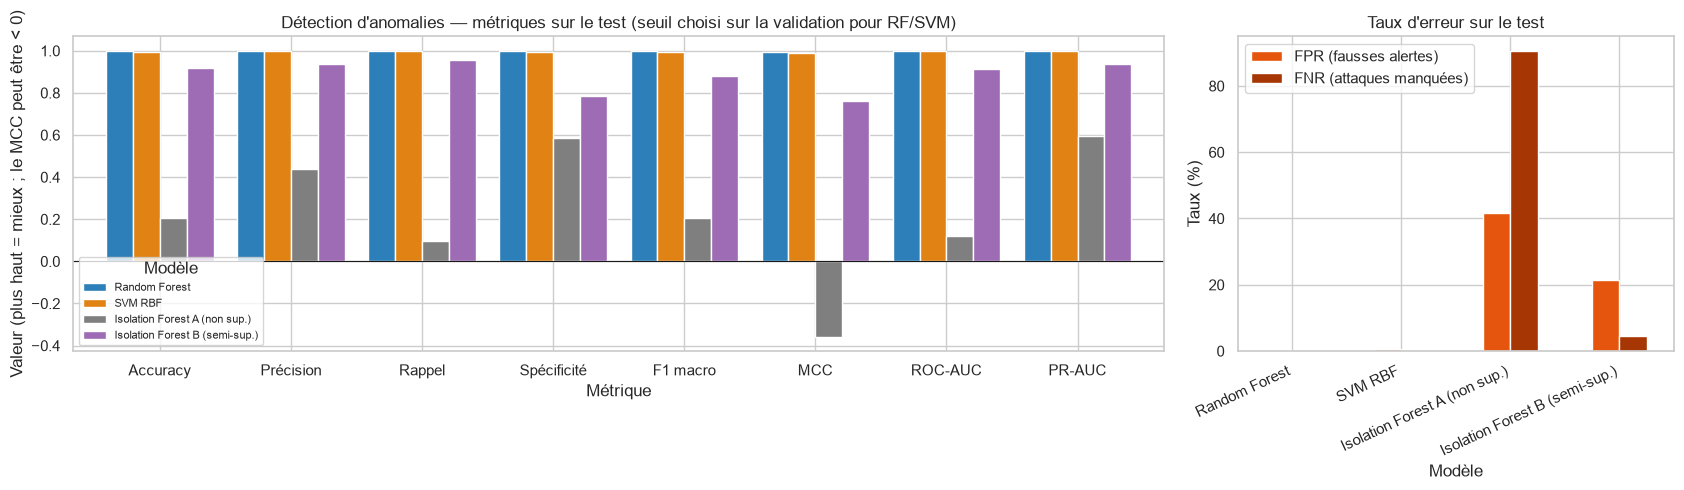

In [9]:
# 4.1 Métriques du tableau A (barres groupées) + taux d'erreur
m_cols = ["accuracy", "precision", "recall", "specificity", "f1_macro", "mcc", "roc_auc", "pr_auc"]
labels = {"accuracy": "Accuracy", "precision": "Précision", "recall": "Rappel", "specificity": "Spécificité",
          "f1_macro": "F1 macro", "mcc": "MCC", "roc_auc": "ROC-AUC", "pr_auc": "PR-AUC"}
short_A = {NAME_RF: "Random Forest", NAME_SVM: "SVM RBF", NAME_IFA: "Isolation Forest A (non sup.)",
           NAME_IFB: "Isolation Forest B (semi-sup.)"}
pal = dict(zip(short_A.values(), ["#2c7fb8", "#e08214", "#7f7f7f", "#9e6bb5"]))
fig, axes = plt.subplots(1, 2, figsize=(17, 5), gridspec_kw={"width_ratios": [3, 1.2]})
d = tab_A.set_index("modèle")[m_cols].rename(index=short_A, columns=labels).T
d.plot(kind="bar", ax=axes[0], width=.82, color=[pal[c] for c in d.columns])
axes[0].set(title="Détection d'anomalies — métriques sur le test (seuil choisi sur la validation pour RF/SVM)",
            xlabel="Métrique", ylabel="Valeur (plus haut = mieux ; le MCC peut être < 0)")
axes[0].axhline(0, color="k", lw=.8); axes[0].tick_params(axis="x", rotation=0); axes[0].legend(title="Modèle", fontsize=8, loc="lower left")
e = tab_A.set_index("modèle")[["fpr", "fnr"]].mul(100).rename(index=short_A, columns={"fpr": "FPR (fausses alertes)", "fnr": "FNR (attaques manquées)"})
e.plot(kind="bar", ax=axes[1], color=["#e6550d", "#a63603"])
axes[1].set(title="Taux d'erreur sur le test", xlabel="Modèle", ylabel="Taux (%)"); axes[1].tick_params(axis="x", rotation=25)
plt.setp(axes[1].get_xticklabels(), ha="right")
fig.tight_layout(); U.savefig(fig, "07_anomaly_metrics"); plt.show()

,AUC recalculée,AUC JSON,écart absolu
Random Forest,0.999960,0.999960,0.000000
SVM RBF,0.998908,0.998908,0.000000
Isolation Forest A (non sup.),0.118833,0.118833,0.000000
Isolation Forest B (semi-sup.),0.915628,0.915628,0.000000


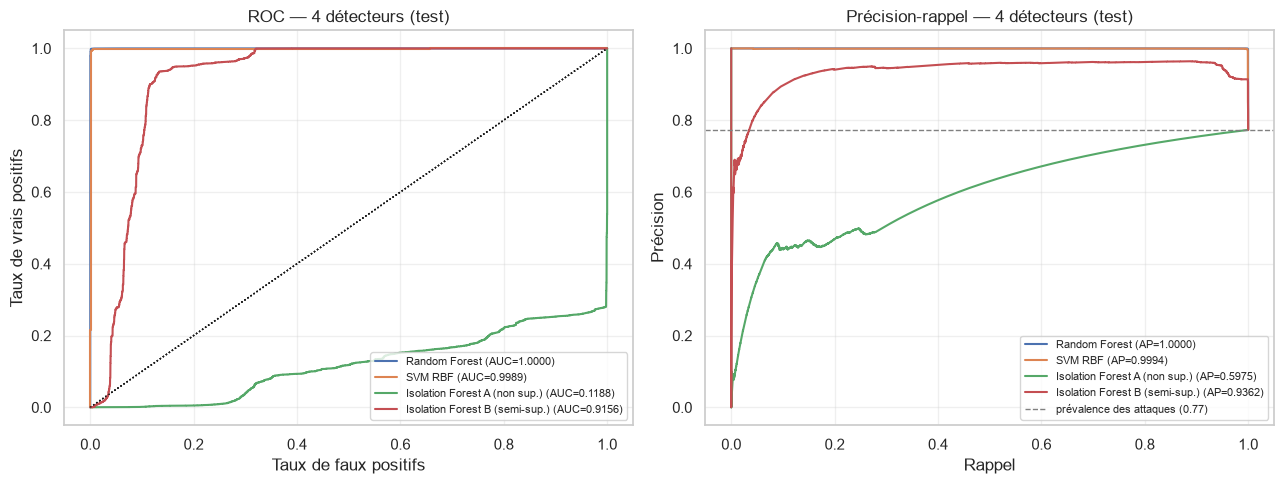

In [10]:
# 4.2 ROC + PR superposées sur le test (modèles rechargés depuis models/) ; le test n'est lu ici que pour l'évaluation
from sklearn.metrics import roc_auc_score
Xte, yte_df = U.load_split("test"); yb = yte_df["label"].to_numpy()
rf_m = joblib.load(U.MODEL_DIR / "rf_anomaly.joblib"); svm_m = joblib.load(U.MODEL_DIR / "svm_anomaly.joblib")
ifa_m = joblib.load(U.MODEL_DIR / "isolation_forest.joblib"); ifb_m = joblib.load(U.MODEL_DIR / "isolation_forest_semisup.joblib")
scores = {"Random Forest": rf_m.predict_proba(Xte)[:, 1], "SVM RBF": svm_m.decision_function(Xte),
          "Isolation Forest A (non sup.)": -ifa_m.score_samples(Xte), "Isolation Forest B (semi-sup.)": -ifb_m.score_samples(Xte)}

# cohérence avec les JSON (même AUC que celle enregistrée dans les notebooks)
ref_auc = dict(zip(scores, [rf["test"]["roc_auc"], svm["test"]["roc_auc"], iso["test"]["roc_auc"], iso_B["roc_auc"]]))
chk = pd.DataFrame({"AUC recalculée": {k: roc_auc_score(yb, s) for k, s in scores.items()}, "AUC JSON": ref_auc})
chk["écart absolu"] = (chk["AUC recalculée"] - chk["AUC JSON"]).abs(); display(chk.style.format("{:.6f}"))
assert chk["écart absolu"].max() < 1e-3, "les modèles rechargés ne reproduisent pas les AUC enregistrées"

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name, s in scores.items():
    U.plot_roc_pr(yb, s, name, axes=axes)
axes[0].set_title("ROC — 4 détecteurs (test)"); axes[1].set_title("Précision-rappel — 4 détecteurs (test)")
axes[1].axhline(yb.mean(), color="gray", ls="--", lw=1, label=f"prévalence des attaques ({yb.mean():.2f})")
for a_ in axes: a_.legend(loc="lower right", fontsize=8)
fig.tight_layout(); U.savefig(fig, "07_roc_pr_detectors"); plt.show()

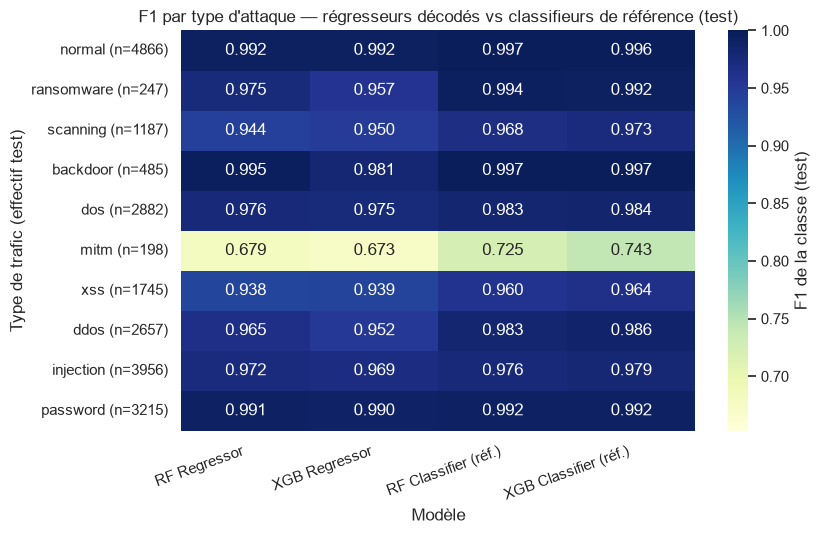

Type le plus difficile par modèle : **RF Regressor** → mitm (0.679) ; **XGB Regressor** → mitm (0.673) ; **RF Classifier (réf.)** → mitm (0.725) ; **XGB Classifier (réf.)** → mitm (0.743)

In [11]:
# 4.3 Carte de chaleur : F1 par type d'attaque pour les 4 modèles de type (lu dans les JSON)
types = prep["type_order"]
f1c = pd.DataFrame({
    "RF Regressor": {t: R["04_rf_regressor"]["per_class"][t]["f1"] for t in types},
    "XGB Regressor": {t: R["05_xgb_regressor"]["per_class"][t]["f1"] for t in types},
    "RF Classifier (réf.)": {t: R["04_rf_regressor"]["reference_classifier"]["per_class"][t]["f1"] for t in types},
    "XGB Classifier (réf.)": {t: R["05_xgb_regressor"]["reference_classifier"]["per_class"][t]["f1"] for t in types},
})
support = {t: R["04_rf_regressor"]["per_class"][t]["support"] for t in types}
f1c.index = [f"{t} (n={support[t]})" for t in types]
fig, ax = plt.subplots(figsize=(8.5, 5.5))
sns.heatmap(f1c, annot=True, fmt=".3f", cmap="YlGnBu", vmin=float(f1c.values.min()) - .02, vmax=1, ax=ax, cbar_kws={"label": "F1 de la classe (test)"})
ax.set(title="F1 par type d'attaque — régresseurs décodés vs classifieurs de référence (test)",
       xlabel="Modèle", ylabel="Type de trafic (effectif test)")
plt.setp(ax.get_xticklabels(), rotation=20, ha="right")
fig.tight_layout(); U.savefig(fig, "07_f1_per_class_heatmap"); plt.show()
worst = f1c.idxmin().map(lambda s: s.split(" (")[0])
display(Markdown("Type le plus difficile par modèle : " + " ; ".join(f"**{m}** → {t} ({f1c[m].min():.3f})" for m, t in worst.items())))

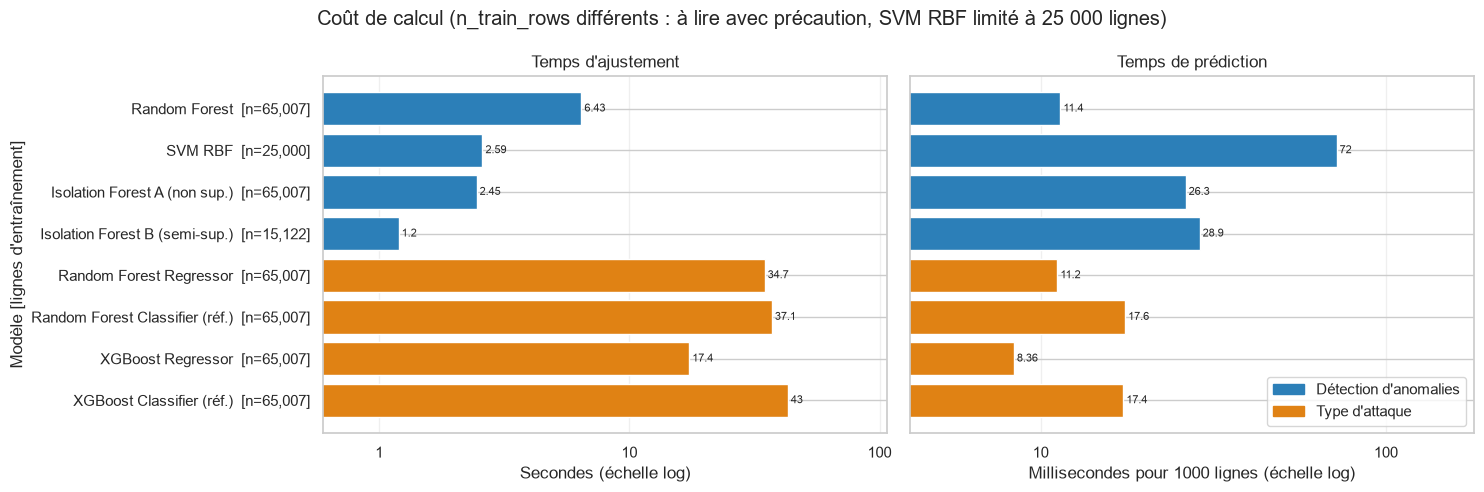

In [12]:
# 4.4 Temps d'ajustement et de prédiction (échelle logarithmique) — tous les modèles
T = pd.concat([tab_A.assign(tâche="Anomalie"), tab_B.assign(tâche="Type")], ignore_index=True)
T["court"] = T["modèle"].replace(short_A).str.replace(r" \(référence.*\)", " (réf.)", regex=True)
T["court"] = T["court"] + "  [n=" + T["n_train_rows"].map("{:,.0f}".format) + "]"
fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
col = T["tâche"].map({"Anomalie": "#2c7fb8", "Type": "#e08214"})
axes[0].barh(T["court"], T["fit_time_s"], color=col); axes[0].set(xscale="log", title="Temps d'ajustement", xlabel="Secondes (échelle log)", ylabel="Modèle [lignes d'entraînement]")
axes[1].barh(T["court"], T["predict_time_ms_per_1k"], color=col); axes[1].set(xscale="log", title="Temps de prédiction", xlabel="Millisecondes pour 1000 lignes (échelle log)")
for a_, c in zip(axes, ["fit_time_s", "predict_time_ms_per_1k"]):
    for i, v in enumerate(T[c]): a_.text(v, i, f" {v:.3g}", va="center", fontsize=8)
    a_.grid(axis="x", alpha=.3)
axes[0].invert_yaxis()
from matplotlib.ticker import FuncFormatter, NullFormatter
for a_, c in zip(axes, ["fit_time_s", "predict_time_ms_per_1k"]):
    a_.set_xlim(T[c].min() / 2, T[c].max() * 2.5)   # axe log : les barres partent de la borne gauche
    a_.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}")); a_.xaxis.set_minor_formatter(NullFormatter())
from matplotlib.patches import Patch
axes[1].legend(handles=[Patch(color="#2c7fb8", label="Détection d'anomalies"), Patch(color="#e08214", label="Type d'attaque")], loc="lower right")
fig.suptitle("Coût de calcul (n_train_rows différents : à lire avec précaution, SVM RBF limité à 25 000 lignes)")
fig.tight_layout(); U.savefig(fig, "07_times"); plt.show()

## 5. Contrôle de robustesse : le modèle s'appuie-t-il sur des raccourcis ?

**Pourquoi.** Même après correction des fuites (déduplication inter-splits, retrait des IP et du port source), les scores restent très élevés (≈ 0,997 de F1 macro pour la détection). Un score aussi haut peut signifier deux choses : le problème est réellement séparable dans ce banc d'essai, **ou** le modèle exploite quelques indices triviaux qui ne se transféreront pas (numéro de port de destination, service, protocole, état de la connexion...).

**Protocole** (sur la **validation uniquement** — le test n'est pas lu ici) : Random Forest (100 arbres, stratégie `none`, 3 graines → moyenne ± écart-type) sur des ensembles de variables de plus en plus pauvres, plus des **références simples** : arbres de décision de profondeur 1, 2, 3 et classe majoritaire. Si un arbre de profondeur 3 (8 feuilles au plus) fait presque aussi bien que la forêt, le jeu de données est « facile » et le score ne mesure pas une capacité de détection générale.

In [13]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.dummy import DummyClassifier

Xtr, ytr_df = U.load_split("train"); Xva, yva_df = U.load_split("valid")
ytr, yva = ytr_df["label"].to_numpy(), yva_df["label"].to_numpy()
num_all, cat_all = cfg["numeric_cols"], cfg["categorical_cols"]
ALL = num_all + cat_all

PORT_ONLY = ["dst_port", "dst_port_bucket"]
IDENTITY = ["dst_port", "dst_port_bucket", "src_port_bucket", "service", "proto", "dns_qclass", "dns_rcode", "dns_AA",
            "dns_RD", "dns_RA", "dns_rejected", "http_status_code", "has_http", "has_ssl"]   # ports, service, protocole, DNS, HTTP/SSL
VOLUME_TIMING = ["duration", "src_bytes", "dst_bytes", "missed_bytes", "src_pkts", "src_ip_bytes", "dst_pkts", "dst_ip_bytes",
                 "total_bytes", "total_pkts", "bytes_ratio", "pkts_ratio", "bytes_per_sec", "pkts_per_sec",
                 "ip_overhead_src", "ip_overhead_dst"]
for nm, cols in [("PORT_ONLY", PORT_ONLY), ("IDENTITY", IDENTITY), ("VOLUME_TIMING", VOLUME_TIMING)]:
    assert set(cols) <= set(ALL), (nm, set(cols) - set(ALL))

ka, kb, kc, ke, kd = ("(a) toutes les variables", "(b) sans dst_port / dst_port_bucket",
                      "(c) sans port / service / protocole / DNS / HTTP / SSL", "(e) comme (c) et sans conn_state",
                      "(d) volumes et durées seulement")
FEATURE_SETS = {ka: ALL, kb: [c for c in ALL if c not in PORT_ONLY], kc: [c for c in ALL if c not in IDENTITY],
                ke: [c for c in ALL if c not in IDENTITY and c != "conn_state"], kd: VOLUME_TIMING}
METRICS_R = ["f1_macro", "specificity", "recall", "mcc"]
SEEDS = [U.RANDOM_STATE, U.RANDOM_STATE + 1, U.RANDOM_STATE + 2]

def fit_eval(estimator, cols):
    """Ajuste sur le train (pipeline sans rééquilibrage) et évalue sur la VALIDATION."""
    n = [c for c in cols if c in num_all]; k = [c for c in cols if c in cat_all]
    pipe = U.make_model_pipeline(estimator, n, k, strategy="none").fit(Xtr[cols], ytr)
    return pipe, U.binary_metrics(yva, pipe.predict(Xva[cols]))

records = []
for name, cols in FEATURE_SETS.items():
    ms = [fit_eval(RandomForestClassifier(n_estimators=100, n_jobs=6, random_state=s), cols)[1] for s in SEEDS]
    rec = {"configuration": name, "type": "Random Forest", "n_features": len(cols)}
    for k in METRICS_R:
        v = np.array([m[k] for m in ms]); rec[k] = v.mean(); rec[k + "_std"] = v.std(ddof=0)
    records.append(rec)

TREE_NAME = lambda d: f"arbre de décision, profondeur {d} (toutes variables)"
tree_rules = {}
for depth in (1, 2, 3):
    pipe, m = fit_eval(DecisionTreeClassifier(max_depth=depth, random_state=U.RANDOM_STATE), ALL)
    names = list(U.feature_names(pipe["pre"]))
    tree_rules[depth] = {"root_feature": names[pipe["model"].tree_.feature[0]],
                         "rules": export_text(pipe["model"], feature_names=names, max_depth=depth)}
    records.append({"configuration": TREE_NAME(depth), "type": "Référence simple", "n_features": len(ALL),
                    **{k: m[k] for k in METRICS_R}, **{k + "_std": 0.0 for k in METRICS_R}})
_, m = fit_eval(DummyClassifier(strategy="most_frequent"), ALL)
records.append({"configuration": "classe majoritaire", "type": "Référence simple", "n_features": 0,
                **{k: m[k] for k in METRICS_R}, **{k + "_std": 0.0 for k in METRICS_R}})

rob = pd.DataFrame(records)
cols_show = ["configuration", "type", "n_features"] + [c for k in METRICS_R for c in (k, k + "_std")]
display(rob[cols_show].style.format({c: "{:.4f}" for c in cols_show[3:]}).background_gradient(subset=["f1_macro"], cmap="Blues"))
for d_, t in tree_rules.items():
    print(f"--- arbre profondeur {d_} (variable à la racine : {t['root_feature']})\n{t['rules']}")

,configuration,type,n_features,f1_macro,f1_macro_std,specificity,specificity_std,recall,recall_std,mcc,mcc_std
0,(a) toutes les variables,Random Forest,35,0.9969,0.0000,0.9942,0.0001,0.9989,0.0000,0.9938,0.0001
1,(b) sans dst_port / dst_port_bucket,Random Forest,33,0.9963,0.0001,0.9919,0.0001,0.9990,0.0000,0.9926,0.0001
2,(c) sans port / service / protocole / DNS / HTTP / SSL,Random Forest,21,0.9957,0.0002,0.9906,0.0002,0.9989,0.0003,0.9914,0.0005
3,(e) comme (c) et sans conn_state,Random Forest,20,0.9948,0.0001,0.9895,0.0003,0.9984,0.0001,0.9897,0.0001
4,(d) volumes et durées seulement,Random Forest,16,0.9923,0.0002,0.9851,0.0003,0.9974,0.0002,0.9846,0.0004
5,"arbre de décision, profondeur 1 (toutes variables)",Référence simple,35,0.8069,0.0000,0.5978,0.0000,0.9602,0.0000,0.6278,0.0000
6,"arbre de décision, profondeur 2 (toutes variables)",Référence simple,35,0.8837,0.0000,0.9132,0.0000,0.9118,0.0000,0.7744,0.0000
7,"arbre de décision, profondeur 3 (toutes variables)",Référence simple,35,0.9599,0.0000,0.9116,0.0000,0.9902,0.0000,0.9204,0.0000
8,classe majoritaire,Référence simple,0,0.4355,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000


--- arbre profondeur 1 (variable à la racine : conn_state_S0)
|--- conn_state_S0 <= 0.50
|   |--- class: 1
|--- conn_state_S0 >  0.50
|   |--- class: 0

--- arbre profondeur 2 (variable à la racine : conn_state_S0)
|--- conn_state_S0 <= 0.50
|   |--- ip_overhead_src <= 3.40
|   |   |--- class: 0
|   |--- ip_overhead_src >  3.40
|   |   |--- class: 1
|--- conn_state_S0 >  0.50
|   |--- ip_overhead_src <= 3.87
|   |   |--- class: 1
|   |--- ip_overhead_src >  3.87
|   |   |--- class: 0

--- arbre profondeur 3 (variable à la racine : conn_state_S0)
|--- conn_state_S0 <= 0.50
|   |--- ip_overhead_src <= 3.40
|   |   |--- bytes_ratio <= 0.41
|   |   |   |--- class: 0
|   |   |--- bytes_ratio >  0.41
|   |   |   |--- class: 1
|   |--- ip_overhead_src >  3.40
|   |   |--- dns_RD_F <= 0.50
|   |   |   |--- class: 1
|   |   |--- dns_RD_F >  0.50
|   |   |   |--- class: 0
|--- conn_state_S0 >  0.50
|   |--- ip_overhead_src <= 3.87
|   |   |--- class: 1
|   |--- ip_overhead_src >  3.87
|   |   |-

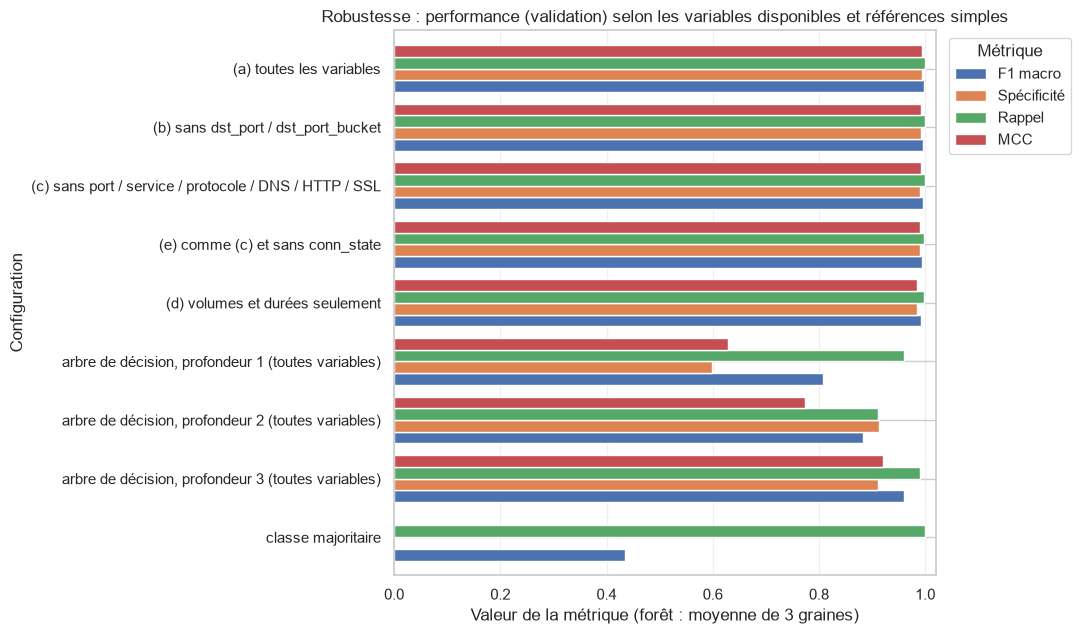

In [14]:
# Figure : barres des quatre métriques par configuration (validation)
plot_df = rob.set_index("configuration")[METRICS_R].rename(columns={"f1_macro": "F1 macro", "specificity": "Spécificité", "recall": "Rappel", "mcc": "MCC"})
fig, ax = plt.subplots(figsize=(11, 6.5))
plot_df.iloc[::-1].plot(kind="barh", ax=ax, width=.8)
ax.set(title="Robustesse : performance (validation) selon les variables disponibles et références simples",
       xlabel="Valeur de la métrique (forêt : moyenne de 3 graines)", ylabel="Configuration", xlim=(0, 1.02))
ax.legend(title="Métrique", loc="upper left", bbox_to_anchor=(1.01, 1)); ax.grid(axis="x", alpha=.3)
fig.tight_layout(); U.savefig(fig, "07_robustness"); plt.show()

# Exports : tableau C + JSON
rob_out = rob[cols_show].copy()
rob_out.round(4).to_csv(REPORT / "table_C_robustness.csv", index=False, encoding="utf-8")
(REPORT / "table_C_robustness.md").write_text(
    "# Tableau C — contrôle de robustesse (validation)\n\n" + rob_out.to_markdown(index=False, floatfmt=".4f") + "\n", encoding="utf-8")
U.save_result("07_robustness", {
    "task": "contrôle de robustesse aux raccourcis (détection binaire, VALIDATION uniquement)",
    "protocol": "RandomForest(100 arbres, 3 graines) strategy none ; arbres profondeur 1-3 ; classe majoritaire ; évaluation sur validation",
    "seeds": SEEDS, "feature_sets": FEATURE_SETS, "table": rob_out.to_dict("records"), "tree_rules": tree_rules,
    "limitations": ["Un seul split aléatoire ; validation seulement (test non lu).",
                    "Les ensembles de variables sont définis a priori : d'autres variables peuvent servir de raccourci.",
                    "Un score élevé sans ports/services ne prouve pas la transférabilité vers un autre réseau."]})

In [15]:
# Interprétation générée à partir des sorties réelles (aucun chiffre saisi à la main)
r = rob.set_index("configuration")
f = lambda k: r.loc[k, "f1_macro"]
maj = f("classe majoritaire"); d1, d2, d3 = (f(TREE_NAME(d)) for d in (1, 2, 3))
gap = lambda x: (x - maj) / (f(ka) - maj)
spec = lambda d: r.loc[TREE_NAME(d), "specificity"]
rec = lambda d: r.loc[TREE_NAME(d), "recall"]
redondant = f(kd) >= 0.98 * f(ka)
root = tree_rules[1]["root_feature"]
phrase_root = (" `conn_state` est l'état de la connexion observé par Zeek (S0 = tentative sans réponse) : un indicateur de comportement de l'outil d'attaque, pas une identité de service, mais très lié au scénario du banc d'essai."
               if root.startswith("conn_state") else "")
phrase_1 = ("Le score est donc **redondant** : plusieurs familles de variables, prises séparément, suffisent à séparer normal et attaque dans ce banc d'essai."
            if redondant else "Retirer ces blocs fait baisser nettement le score : une partie de la performance repose sur eux.")
display(Markdown(f"""
### Interprétation (valeurs lues dans le tableau ci-dessus, validation)

**1. Le modèle ne dépend pas d'un bloc de variables isolé.**
F1 macro avec toutes les variables : **{f(ka):.4f}** ; sans `dst_port` : {f(kb):.4f} ({f(kb)-f(ka):+.4f}) ; sans aucune identité de service/port/protocole/DNS/HTTP/SSL : {f(kc):.4f} ({f(kc)-f(ka):+.4f}) ; et en plus sans `conn_state` : {f(ke):.4f} ({f(ke)-f(ka):+.4f}) ;
**avec uniquement {r.loc[kd,'n_features']:.0f} variables de volume et de durée : {f(kd):.4f} ({f(kd)-f(ka):+.4f})**, soit {f(kd)/f(ka):.1%} du score complet. La spécificité (part des flux normaux correctement laissés passer) passe de {r.loc[ka,'specificity']:.4f} à {r.loc[kd,'specificity']:.4f}.
{phrase_1}

**2. Quelques règles très simples expliquent déjà l'essentiel.**
La classe majoritaire donne un F1 macro de {maj:.4f} (MCC {r.loc['classe majoritaire','mcc']:.4f}). Un arbre à **une seule règle** (variable racine : `{tree_rules[1]['root_feature']}`) atteint {d1:.4f} (spécificité {spec(1):.4f}, rappel {rec(1):.4f}), soit {gap(d1):.1%} de l'écart entre la classe majoritaire et la forêt complète ;
profondeur 2 : {d2:.4f} ({gap(d2):.1%}) ; **profondeur 3 (8 feuilles au plus) : {d3:.4f} ({gap(d3):.1%})**, avec une spécificité de {spec(3):.4f}.
Les variables utilisées par ces règles figurent dans les arbres affichés plus haut.{phrase_root} Le dernier gain (de {d3:.4f} à {f(ka):.4f}) vient de règles plus fines, qui traitent les attaques moins typées et les flux normaux atypiques.

**3. Ce que cela implique pour un autre réseau.**
Ces chiffres écartent l'hypothèse d'un raccourci unique de type « numéro de port » ou « service », mais **ils ne prouvent pas la transférabilité** : le problème est « facile » dans ce jeu de données. Les attaques du banc d'essai TON_IoT sont générées par des outils scriptés, avec des signatures de volume, de taille de paquets et d'état de connexion très régulières ; un modèle, même très simple, apprend ces régularités. Sur un autre réseau, avec un trafic normal différent, d'autres outils d'attaque, des attaques lentes ou furtives, ces signatures peuvent changer : le score observé ici est une **borne haute optimiste**, pas une estimation de la performance en production.
La répartition aléatoire (et non temporelle ou par hôte) laisse en outre des flux issus des mêmes campagnes d'attaque dans le train, la validation et le test, ce qui favorise encore le score. Pour valider la généralisation, il faudrait au minimum un découpage par campagne ou par période, ou un second jeu de données issu d'un autre réseau.
"""))


### Interprétation (valeurs lues dans le tableau ci-dessus, validation)

**1. Le modèle ne dépend pas d'un bloc de variables isolé.**
F1 macro avec toutes les variables : **0.9969** ; sans `dst_port` : 0.9963 (-0.0006) ; sans aucune identité de service/port/protocole/DNS/HTTP/SSL : 0.9957 (-0.0012) ; et en plus sans `conn_state` : 0.9948 (-0.0021) ;
**avec uniquement 16 variables de volume et de durée : 0.9923 (-0.0046)**, soit 99.5% du score complet. La spécificité (part des flux normaux correctement laissés passer) passe de 0.9942 à 0.9851.
Le score est donc **redondant** : plusieurs familles de variables, prises séparément, suffisent à séparer normal et attaque dans ce banc d'essai.

**2. Quelques règles très simples expliquent déjà l'essentiel.**
La classe majoritaire donne un F1 macro de 0.4355 (MCC 0.0000). Un arbre à **une seule règle** (variable racine : `conn_state_S0`) atteint 0.8069 (spécificité 0.5978, rappel 0.9602), soit 66.2% de l'écart entre la classe majoritaire et la forêt complète ;
profondeur 2 : 0.8837 (79.8%) ; **profondeur 3 (8 feuilles au plus) : 0.9599 (93.4%)**, avec une spécificité de 0.9116.
Les variables utilisées par ces règles figurent dans les arbres affichés plus haut. `conn_state` est l'état de la connexion observé par Zeek (S0 = tentative sans réponse) : un indicateur de comportement de l'outil d'attaque, pas une identité de service, mais très lié au scénario du banc d'essai. Le dernier gain (de 0.9599 à 0.9969) vient de règles plus fines, qui traitent les attaques moins typées et les flux normaux atypiques.

**3. Ce que cela implique pour un autre réseau.**
Ces chiffres écartent l'hypothèse d'un raccourci unique de type « numéro de port » ou « service », mais **ils ne prouvent pas la transférabilité** : le problème est « facile » dans ce jeu de données. Les attaques du banc d'essai TON_IoT sont générées par des outils scriptés, avec des signatures de volume, de taille de paquets et d'état de connexion très régulières ; un modèle, même très simple, apprend ces régularités. Sur un autre réseau, avec un trafic normal différent, d'autres outils d'attaque, des attaques lentes ou furtives, ces signatures peuvent changer : le score observé ici est une **borne haute optimiste**, pas une estimation de la performance en production.
La répartition aléatoire (et non temporelle ou par hôte) laisse en outre des flux issus des mêmes campagnes d'attaque dans le train, la validation et le test, ce qui favorise encore le score. Pour valider la généralisation, il faudrait au minimum un découpage par campagne ou par période, ou un second jeu de données issu d'un autre réseau.


## 6. Synthèse et recommandations

Le texte ci-dessous est **généré à partir des tableaux A, B et C** : les chiffres viennent des sorties réelles.

In [16]:
a = tab_A.set_index("modèle"); b = tab_B.set_index("modèle")
detectors = a.loc[[NAME_RF, NAME_SVM]]
best_det = detectors["f1_macro"].idxmax(); other_det = [n for n in detectors.index if n != best_det][0]
regs = b.loc[[n for n in b.index if "Regressor" in n]]
best_reg = regs["f1_macro"].idxmax()
clf_for = {"Random Forest Regressor": ref_names["04_rf_regressor"], "XGBoost Regressor": ref_names["05_xgb_regressor"]}
cost = {n: b.loc[clf_for[n], "f1_macro"] - b.loc[n, "f1_macro"] for n in regs.index}
costm = {n: b.loc[clf_for[n], "mcc"] - b.loc[n, "mcc"] for n in regs.index}
fastest_sup = detectors["predict_time_ms_per_1k"].idxmin()
sens = "inversé : le trafic normal est jugé plus anormal que les attaques" if a.loc[NAME_IFA, "roc_auc"] < .5 else "dans le bon sens"
reco_clf = ("mais **recommander une classification multi-classes** pour un usage réel (les classifieurs de référence font mieux dans les deux familles, écarts ci-dessus)"
            if all(v > 0 for v in cost.values()) else "et comparer avec une classification multi-classes, qui ne fait pas systématiquement mieux ici (écarts ci-dessus)")
cost_txt = "; ".join(f"{n} : F1 macro {cost[n]:+.4f}, MCC {costm[n]:+.4f}" for n in regs.index)
worst_txt = ", ".join(f"{m} → {t}" for m, t in worst.items())
display(Markdown(f"""
### Résultats principaux (test)

**Détection d'anomalies.** Meilleur détecteur par F1 macro : **{best_det}** (F1 macro {detectors.loc[best_det,'f1_macro']:.4f}, MCC {detectors.loc[best_det,'mcc']:.4f}, rappel {detectors.loc[best_det,'recall']:.4f}, spécificité {detectors.loc[best_det,'specificity']:.4f}) devant {other_det} ({detectors.loc[other_det,'f1_macro']:.4f}).
L'écart ({detectors.loc[best_det,'f1_macro'] - detectors.loc[other_det,'f1_macro']:+.4f}) est mesuré sur un seul split sans intervalle de confiance : il ne justifie à lui seul aucune préférence forte.
Le plus rapide en prédiction parmi les supervisés : **{fastest_sup}** ({detectors.loc[fastest_sup,'predict_time_ms_per_1k']:.1f} ms / 1000 lignes) ; ajustement : RF {a.loc[NAME_RF,'fit_time_s']:.1f} s sur {a.loc[NAME_RF,'n_train_rows']:,.0f} lignes, SVM {a.loc[NAME_SVM,'fit_time_s']:.1f} s sur {a.loc[NAME_SVM,'n_train_rows']:,.0f} lignes (RBF exact limité par son coût O(n²)).

**Type d'attaque (régression demandée).** Meilleur régresseur par F1 macro : **{best_reg}** (F1 macro {regs.loc[best_reg,'f1_macro']:.4f}, accuracy équilibrée {regs.loc[best_reg,'balanced_accuracy']:.4f}, MAE {regs.loc[best_reg,'mae']:.4f}, RMSE {regs.loc[best_reg,'rmse']:.4f}, R² {regs.loc[best_reg,'r2']:.4f}).
**Coût de la régression sur une cible nominale** (classifieur de référence moins régresseur, même famille de modèle, mêmes variables) : {cost_txt}.
Un R² élevé ne signifie pas que le type est bien reconnu : le code est un artefact d'ordre (voir 01) et le décodage par points de coupure ne fait que le compenser en partie ; les classifieurs de référence ne sont pas demandés mais montrent ce qu'apporte la formulation naturelle (classification).
Type le plus difficile (carte de chaleur) : {worst_txt}.

**Leçon Isolation Forest.** La détection non supervisée suppose des anomalies **rares** ; ici les attaques représentent {yb.mean():.1%} du test. Résultat mesuré : ROC-AUC de A = {a.loc[NAME_IFA,'roc_auc']:.3f} (score {sens}), MCC = {a.loc[NAME_IFA,'mcc']:.3f}, rappel = {a.loc[NAME_IFA,'recall']:.3f} à la décision par défaut.
Avec les étiquettes « normal » (B, détection de nouveauté) : ROC-AUC {a.loc[NAME_IFB,'roc_auc']:.3f}, rappel {a.loc[NAME_IFB,'recall']:.3f}, mais spécificité {a.loc[NAME_IFB,'specificity']:.3f} (FPR {a.loc[NAME_IFB,'fpr']:.3f}), contre au moins {detectors['specificity'].min():.3f} pour les modèles supervisés.
La stabilité entre graines est élevée (Spearman moyen {iso['stability']['spearman_mean']:.3f}) : l'échec de A vient de l'hypothèse violée, pas du hasard de la forêt. Usage recommandé : détecteur **complémentaire** entraîné sur du trafic normal de référence, pas un remplaçant du supervisé.

**Robustesse (section 5, validation).** Avec les seules variables de volume/durée ({r.loc[kd,'n_features']:.0f} variables) : F1 macro {r.loc[kd,'f1_macro']:.4f} contre {r.loc[ka,'f1_macro']:.4f} avec toutes les variables ; un arbre de profondeur 3 atteint {d3:.4f}. Le score élevé reflète donc surtout la séparabilité du banc d'essai.

### Recommandations
1. **Retenir {best_det}** comme détecteur de référence, en le présentant avec sa spécificité et son FPR (le coût d'une fausse alerte compte autant que le rappel) et non avec la seule accuracy.
2. **Type d'attaque** : conserver le régresseur demandé ({best_reg}) avec décodage par points de coupure appris sur la validation, {reco_clf} ; ne pas interpréter MAE/RMSE/R² comme une qualité de reconnaissance.
3. **Isolation Forest** : ne pas l'utiliser seul sur ce type de données (attaques majoritaires) ; l'entraîner sur du trafic normal sain et le garder comme alarme de nouveauté.
4. Publier systématiquement les **tableaux A, B, C** (`reports/`) avec les nombres de lignes d'entraînement et les temps, pour une comparaison équitable.

### Limites de l'étude entière
- **Un seul jeu de données** (banc d'essai TON_IoT, trafic scripté, attaques majoritaires) : prévalence et diversité non représentatives d'un réseau réel.
- **Découpage aléatoire** (stratifié) et non temporel ni par hôte/campagne : des flux voisins des mêmes campagnes se retrouvent dans train, validation et test ; la généralisation à un autre réseau ou à une autre période n'est pas mesurée.
- **Un seul split, une seule graine** pour les scores finaux : pas d'intervalle de confiance ; les écarts de l'ordre du millième sont indiscernables du bruit. Les classes rares (ex. `mitm`, {R['04_rf_regressor']['per_class']['mitm']['support']} lignes de test) ont un F1 très incertain.
- **Déduplication** : elle retire {prep['n_rows_raw'] - prep['n_rows_clean']:,} lignes sur {prep['n_rows_raw']:,} ; les scores portent sur des flux distincts, pas sur le trafic brut (dont la répartition est différente).
- **Modèles supervisés** : ils ne détectent pas des attaques absentes de l'entraînement ; l'artefact de l'encodage ordinal du type est atténué mais pas supprimé par les points de coupure.
- **Réglages** faits sur des sous-échantillons (CV 3 plis) : les écarts inférieurs à un écart-type ont été traités comme du bruit (règle de parcimonie).
"""))


### Résultats principaux (test)

**Détection d'anomalies.** Meilleur détecteur par F1 macro : **Random Forest** (F1 macro 0.9977, MCC 0.9955, rappel 0.9988, spécificité 0.9971) devant SVM RBF (25k lignes) (0.9950).
L'écart (+0.0028) est mesuré sur un seul split sans intervalle de confiance : il ne justifie à lui seul aucune préférence forte.
Le plus rapide en prédiction parmi les supervisés : **Random Forest** (11.4 ms / 1000 lignes) ; ajustement : RF 6.4 s sur 65,007 lignes, SVM 2.6 s sur 25,000 lignes (RBF exact limité par son coût O(n²)).

**Type d'attaque (régression demandée).** Meilleur régresseur par F1 macro : **Random Forest Regressor** (F1 macro 0.9428, accuracy équilibrée 0.9568, MAE 0.0596, RMSE 0.3812, R² 0.9870).
**Coût de la régression sur une cible nominale** (classifieur de référence moins régresseur, même famille de modèle, mêmes variables) : Random Forest Regressor : F1 macro +0.0146, MCC +0.0105; XGBoost Regressor : F1 macro +0.0228, MCC +0.0156.
Un R² élevé ne signifie pas que le type est bien reconnu : le code est un artefact d'ordre (voir 01) et le décodage par points de coupure ne fait que le compenser en partie ; les classifieurs de référence ne sont pas demandés mais montrent ce qu'apporte la formulation naturelle (classification).
Type le plus difficile (carte de chaleur) : RF Regressor → mitm, XGB Regressor → mitm, RF Classifier (réf.) → mitm, XGB Classifier (réf.) → mitm.

**Leçon Isolation Forest.** La détection non supervisée suppose des anomalies **rares** ; ici les attaques représentent 77.3% du test. Résultat mesuré : ROC-AUC de A = 0.119 (score inversé : le trafic normal est jugé plus anormal que les attaques), MCC = -0.358, rappel = 0.096 à la décision par défaut.
Avec les étiquettes « normal » (B, détection de nouveauté) : ROC-AUC 0.916, rappel 0.956, mais spécificité 0.786 (FPR 0.214), contre au moins 0.994 pour les modèles supervisés.
La stabilité entre graines est élevée (Spearman moyen 0.994) : l'échec de A vient de l'hypothèse violée, pas du hasard de la forêt. Usage recommandé : détecteur **complémentaire** entraîné sur du trafic normal de référence, pas un remplaçant du supervisé.

**Robustesse (section 5, validation).** Avec les seules variables de volume/durée (16 variables) : F1 macro 0.9923 contre 0.9969 avec toutes les variables ; un arbre de profondeur 3 atteint 0.9599. Le score élevé reflète donc surtout la séparabilité du banc d'essai.

### Recommandations
1. **Retenir Random Forest** comme détecteur de référence, en le présentant avec sa spécificité et son FPR (le coût d'une fausse alerte compte autant que le rappel) et non avec la seule accuracy.
2. **Type d'attaque** : conserver le régresseur demandé (Random Forest Regressor) avec décodage par points de coupure appris sur la validation, mais **recommander une classification multi-classes** pour un usage réel (les classifieurs de référence font mieux dans les deux familles, écarts ci-dessus) ; ne pas interpréter MAE/RMSE/R² comme une qualité de reconnaissance.
3. **Isolation Forest** : ne pas l'utiliser seul sur ce type de données (attaques majoritaires) ; l'entraîner sur du trafic normal sain et le garder comme alarme de nouveauté.
4. Publier systématiquement les **tableaux A, B, C** (`reports/`) avec les nombres de lignes d'entraînement et les temps, pour une comparaison équitable.

### Limites de l'étude entière
- **Un seul jeu de données** (banc d'essai TON_IoT, trafic scripté, attaques majoritaires) : prévalence et diversité non représentatives d'un réseau réel.
- **Découpage aléatoire** (stratifié) et non temporel ni par hôte/campagne : des flux voisins des mêmes campagnes se retrouvent dans train, validation et test ; la généralisation à un autre réseau ou à une autre période n'est pas mesurée.
- **Un seul split, une seule graine** pour les scores finaux : pas d'intervalle de confiance ; les écarts de l'ordre du millième sont indiscernables du bruit. Les classes rares (ex. `mitm`, 198 lignes de test) ont un F1 très incertain.
- **Déduplication** : elle retire 102,697 lignes sur 211,043 ; les scores portent sur des flux distincts, pas sur le trafic brut (dont la répartition est différente).
- **Modèles supervisés** : ils ne détectent pas des attaques absentes de l'entraînement ; l'artefact de l'encodage ordinal du type est atténué mais pas supprimé par les points de coupure.
- **Réglages** faits sur des sous-échantillons (CV 3 plis) : les écarts inférieurs à un écart-type ont été traités comme du bruit (règle de parcimonie).
